# SPAM SMS DETECTION
#### ~code by Siddhartha Mettu

### IMPORTS

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


### LOADING DATA

In [2]:
df = pd.read_csv("data/spam.csv", encoding="latin-1")

# Keep only required columns
df = df[['v1', 'v2']]
df.columns = ['label', 'message']

### BASIC CLEANING

In [3]:
df.drop_duplicates(inplace=True)
df.dropna(inplace=True)

# Encode target
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

### EXPLORATORY DATA ANALYSIS

##### Dataset Shape

In [4]:
print("Shape:", df.shape)

Shape: (5169, 2)


##### Class distribution


Class Distribution:
 label
0    4516
1     653
Name: count, dtype: int64


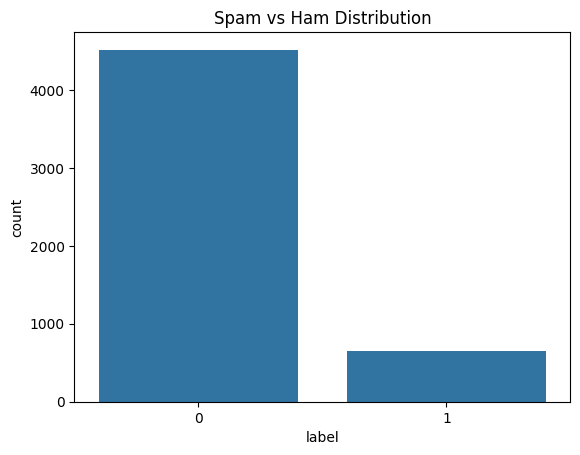

In [5]:
print("\nClass Distribution:\n", df['label'].value_counts())

plt.figure()
sns.countplot(x=df['label'])
plt.title("Spam vs Ham Distribution")
plt.show()

##### Message length

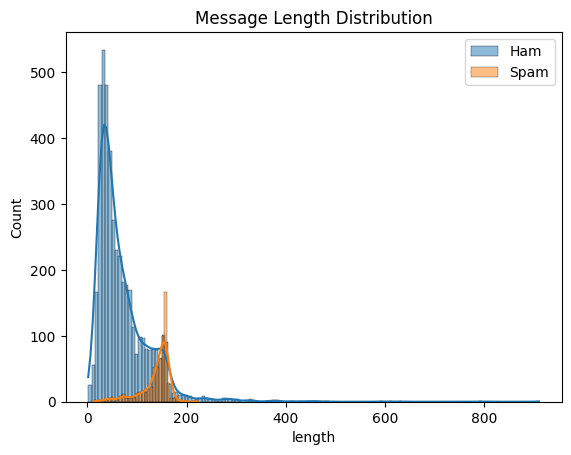

In [6]:
df['length'] = df['message'].apply(len)

plt.figure()
sns.histplot(df[df['label']==0]['length'], label='Ham', kde=True)
sns.histplot(df[df['label']==1]['length'], label='Spam', kde=True)
plt.legend()
plt.title("Message Length Distribution")
plt.show()


##### Word count

In [8]:
df['word_count'] = df['message'].apply(lambda x: len(x.split()))
print("\nAvg Word Count:\n", df.groupby('label')['word_count'].mean())



Avg Word Count:
 label
0    14.134632
1    23.681470
Name: word_count, dtype: float64


##### Character Usage

In [9]:
# 6. Special characters count
df['special_chars'] = df['message'].apply(lambda x: len([c for c in x if c in string.punctuation]))

# 7. Uppercase usage
df['uppercase'] = df['message'].apply(lambda x: sum(1 for c in x if c.isupper()))


##### Correlation heatmap

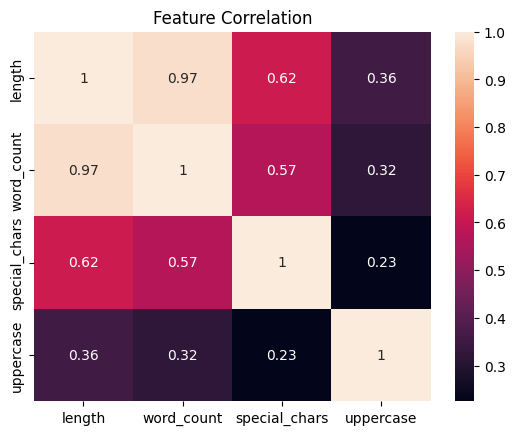

In [10]:
plt.figure()
sns.heatmap(df[['length','word_count','special_chars','uppercase']].corr(), annot=True)
plt.title("Feature Correlation")
plt.show()

##### Boxplot of message length

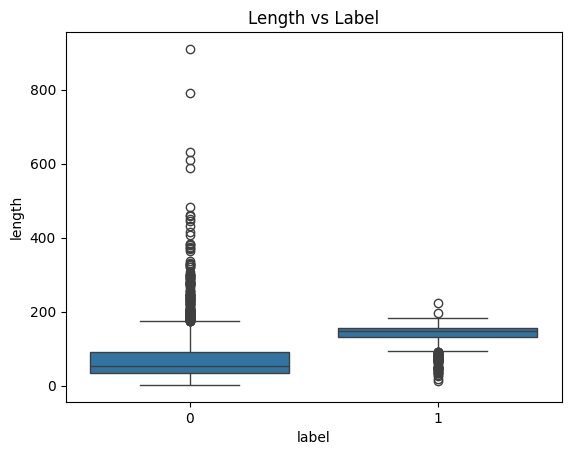

In [11]:

plt.figure()
sns.boxplot(x='label', y='length', data=df)
plt.title("Length vs Label")
plt.show()


##### WORD CLOUD VISUALIZATION

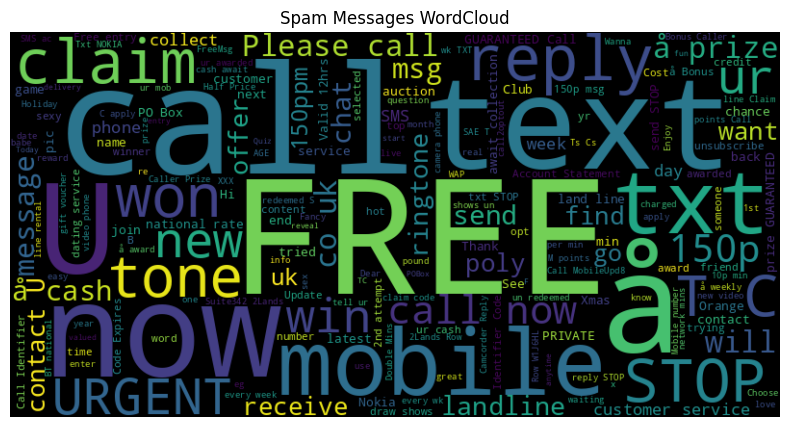

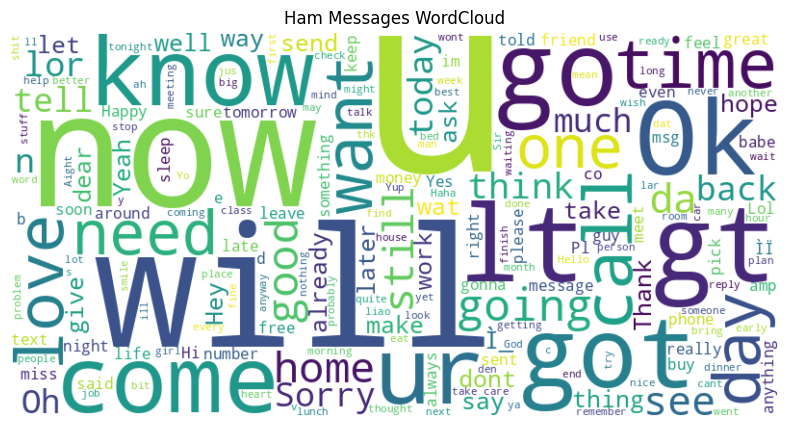

In [12]:

from wordcloud import WordCloud

# Combine all spam and ham text
spam_text = " ".join(df[df['label'] == 1]['message'])
ham_text = " ".join(df[df['label'] == 0]['message'])

# Spam WordCloud
plt.figure(figsize=(10,5))
spam_wc = WordCloud(width=800, height=400, background_color='black').generate(spam_text)
plt.imshow(spam_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Spam Messages WordCloud")
plt.show()

# Ham WordCloud
plt.figure(figsize=(10,5))
ham_wc = WordCloud(width=800, height=400, background_color='white').generate(ham_text)
plt.imshow(ham_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Ham Messages WordCloud")
plt.show()

##### Top words in spam vs ham

In [13]:

from collections import Counter

spam_words = Counter(" ".join(df[df['label']==1]['message']).split()).most_common(10)
ham_words = Counter(" ".join(df[df['label']==0]['message']).split()).most_common(10)

print("\nTop Spam Words:", spam_words)
print("\nTop Ham Words:", ham_words)

# 11. Message examples
print("\nSample Spam:\n", df[df['label']==1]['message'].iloc[0])
print("\nSample Ham:\n", df[df['label']==0]['message'].iloc[0])



Top Spam Words: [('to', 522), ('a', 314), ('your', 171), ('call', 163), ('the', 160), ('or', 155), ('for', 152), ('2', 151), ('you', 150), ('is', 130)]

Top Ham Words: [('to', 1450), ('you', 1412), ('I', 1349), ('the', 954), ('a', 884), ('i', 714), ('and', 712), ('in', 677), ('u', 576), ('my', 570)]

Sample Spam:
 Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's

Sample Ham:
 Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...


### TEXT PREPROCESSING


In [14]:


def clean_text(text):
    text = text.lower()
    text = re.sub(r'\d+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = text.strip()
    return text

df['message'] = df['message'].apply(clean_text)

### TRAIN TEST SPLIT

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    df['message'], df['label'], test_size=0.2, random_state=42
)

### MODEL PIPELINES

In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "SVM": SVC(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "KNN": KNeighborsClassifier()
}

results = {}

### TRAINING + EVALUATION

In [17]:
for name, model in models.items():
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english')),
        ('model', model)
    ])
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    
    print(f"\n{name}")
    print("Accuracy:", acc)
    print(classification_report(y_test, y_pred))


Logistic Regression
Accuracy: 0.9535783365570599
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       889
           1       0.99      0.68      0.80       145

    accuracy                           0.95      1034
   macro avg       0.97      0.84      0.89      1034
weighted avg       0.96      0.95      0.95      1034


Naive Bayes
Accuracy: 0.9593810444874274
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       889
           1       1.00      0.71      0.83       145

    accuracy                           0.96      1034
   macro avg       0.98      0.86      0.90      1034
weighted avg       0.96      0.96      0.96      1034


SVM
Accuracy: 0.9738878143133463
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       889
           1       0.98      0.83      0.90       145

    accuracy                           0.97      1034
  

 ### MODEL COMPARISON

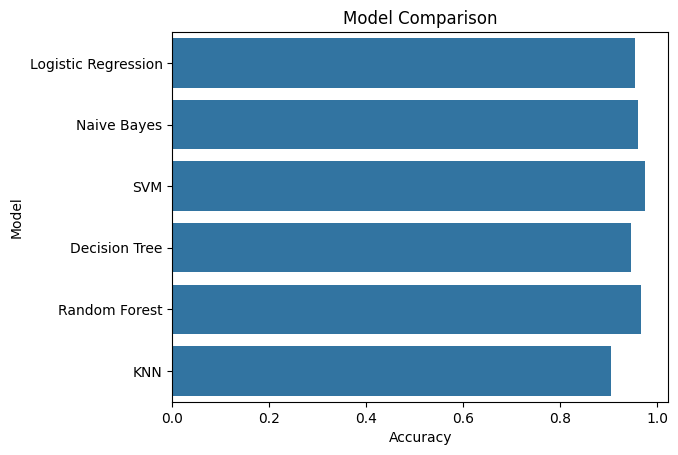

In [18]:
results_df = pd.DataFrame(list(results.items()), columns=['Model', 'Accuracy'])

plt.figure()
sns.barplot(x='Accuracy', y='Model', data=results_df)
plt.title("Model Comparison")
plt.show()

### BEST MODEL SELECTION

In [20]:

best_model_name = max(results, key=results.get)
print("\n🏆 Best Model:", best_model_name)
print("Best Accuracy:", results[best_model_name])



🏆 Best Model: SVM
Best Accuracy: 0.9738878143133463


### CONFUSION MATRIX FOR BEST MODEL


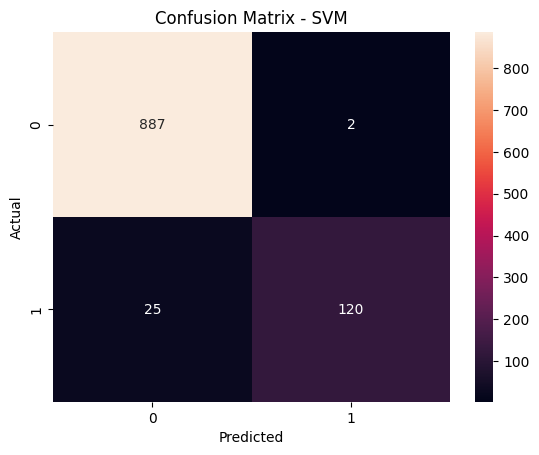

In [21]:

best_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english')),
    ('model', models[best_model_name])
])

best_pipeline.fit(X_train, y_train)
y_pred_best = best_pipeline.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()